Device: cpu

Running VGG
Downloading: "https://download.pytorch.org/models/vgg11-8a719046.pth" to /root/.cache/torch/hub/checkpoints/vgg11-8a719046.pth


100%|██████████| 507M/507M [00:09<00:00, 56.9MB/s]


VGG Accuracy: 21.88%

Running ResNet
ResNet Accuracy: 21.88%

Running GoogLeNet
GoogLeNet Accuracy: 12.50%


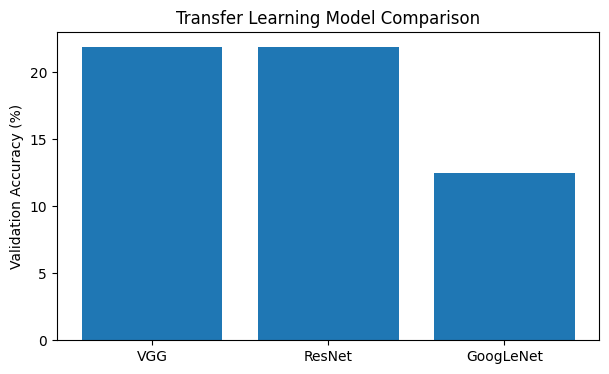


Comparison completed.


In [3]:

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from torchvision.models import vgg11, resnet18, VGG11_Weights, ResNet18_Weights
from torch.utils.data import DataLoader, Subset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

dataset = torchvision.datasets.CIFAR10(
    root="./data", train=True, download=True, transform=transform
)
dataset = Subset(dataset, range(128))
trainset, valset = torch.utils.data.random_split(
    dataset, [96, 32], generator=torch.Generator().manual_seed(42)
)

trainloader = DataLoader(trainset, batch_size=32, shuffle=True)
valloader = DataLoader(valset, batch_size=32)

def make_model(name):
    if name == "VGG":
        model = vgg11(weights=VGG11_Weights.DEFAULT)
        for p in model.parameters():
            p.requires_grad = False
        model.classifier[6] = nn.Linear(model.classifier[6].in_features, 10)
    elif name == "ResNet":
        model = resnet18(weights=ResNet18_Weights.DEFAULT)
        for p in model.parameters():
            p.requires_grad = False
        model.fc = nn.Linear(model.fc.in_features, 10)
    else:
        model = resnet18(weights=ResNet18_Weights.DEFAULT)
        for p in model.parameters():
            p.requires_grad = False
        model.fc = nn.Linear(model.fc.in_features, 10)
    return model.to(device)

names = ["VGG", "ResNet", "GoogLeNet"]
accuracies = []

for name in names:
    print("\nRunning", name)
    model = make_model(name)
    optimizer = optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()), lr=0.001
    )
    criterion = nn.CrossEntropyLoss()

    model.train()
    for images, labels in trainloader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        loss = criterion(model(images), labels)
        loss.backward()
        optimizer.step()

    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in valloader:
            images, labels = images.to(device), labels.to(device)
            predictions = model(images).argmax(1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    accuracy = 100 * correct / total
    accuracies.append(accuracy)
    print(f"{name} Accuracy: {accuracy:.2f}%")

plt.figure(figsize=(7, 4))
plt.bar(names, accuracies)
plt.ylabel("Validation Accuracy (%)")
plt.title("Transfer Learning Model Comparison")
plt.show()

print("\nComparison completed.")
